<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS13/praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 3: Regresi Menggunakan Keras (Prediksi Harga Rumah)

Praktikum 3 kali ini kita akan mencoba menggunakan Keras untuk Regresi, khususnya pada kasus Prediksi Harga Rumah.

### Tahapan Praktikum:
1. **Regresi Sederhana dengan Dummy Data**: Membangun model regresi dasar dengan input fitur luas dan target harga rumah.
2. **Tugas 4**: Mengubah nilai *learning rate* dan membandingkan hasil loss.
3. **MLP Regresi dengan Dataset Boston Housing**: Memprediksi harga rumah menggunakan multi-layer perceptron (MLP) dengan dataset Boston yang lebih kompleks.

### Bagian 1: Contoh Dataset Regresi Sederhana (Dummy Data Luas & Harga)
Membuat dummy data luas rumah dan harga, melakukan standardisasi fitur (*StandardScaler*), membagi data latih dan uji, lalu membangun model regresi sederhana dengan Keras.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
history_dummy = model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi
pred_dummy = model.predict(X_test)
loss_baseline_dummy = model.evaluate(X_test, y_test, verbose=0)

print("=== HASIL MODEL DUMMY (KONFIGURASI AWAL) ===")
print("Prediksi Nilai Terstandarisasi :", pred_dummy.ravel())
print("Target Sebenarnya              :", y_test.ravel())
print(f"Loss Evaluasi (MSE)            : {loss_baseline_dummy:.6f}")

c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
=== HASIL MODEL DUMMY (KONFIGURASI AWAL) ===
Prediksi Nilai Terstandarisasi : [-0.26258272]
Target Sebenarnya              : [-0.70710678]
Loss Evaluasi (MSE)            : 0.197602


---
# Tugas 4
1. **Ubah learning rate.**
2. **Bandingkan hasil loss.**

### Eksperimen Tugas 4: Variasi Learning Rate pada Optimizer Adam
Pada tugas ini, kita menguji 4 variasi nilai *learning rate* pada optimizer Adam untuk melatih model regresi dengan arsitektur yang sama selama 100 epoch:
- $\text{lr} = 0.0001$ (*learning rate* sangat kecil)
- $\text{lr} = 0.001$ (*default learning rate* Adam)
- $\text{lr} = 0.01$ (*learning rate* moderat)
- $\text{lr} = 0.1$ (*learning rate* besar)

In [2]:
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

# Daftar variasi learning rate yang akan diuji
learning_rates = [0.0001, 0.001, 0.01, 0.1]
histories_lr = {}
test_losses_lr = {}

for lr in learning_rates:
    # Set seed agar inisialisasi bobot seragam
    tf.random.set_seed(42)
    np.random.seed(42)
    
    # Bangun arsitektur model yang sama
    m_lr = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    
    # Kompilasi dengan learning rate yang diubah
    m_lr.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    
    # Latih model selama 100 epoch
    h_lr = m_lr.fit(X_train, y_train, epochs=100, verbose=0)
    
    # Evaluasi pada data uji
    loss_eval = m_lr.evaluate(X_test, y_test, verbose=0)
    
    histories_lr[lr] = h_lr.history['loss']
    test_losses_lr[lr] = loss_eval
    
    print(f"Learning Rate = {lr:<6} | Final Train Loss: {h_lr.history['loss'][-1]:.6f} | Test Loss: {loss_eval:.6f}")

Learning Rate = 0.0001 | Final Train Loss: 0.870736 | Test Loss: 0.268202
Learning Rate = 0.001  | Final Train Loss: 0.725860 | Test Loss: 0.559823
Learning Rate = 0.01   | Final Train Loss: 0.002567 | Test Loss: 0.008276
Learning Rate = 0.1    | Final Train Loss: 0.000013 | Test Loss: 0.016244


### Perbandingan Hasil Loss Berdasarkan Learning Rate
Tabel perbandingan nilai loss akhir serta grafik konvergensi penurunan loss selama 100 epoch untuk masing-masing nilai *learning rate*.

=== TABEL PERBANDINGAN HASIL LOSS DENGAN VARIASI LEARNING RATE ===


,Learning Rate,Train Loss Awal (Epoch 1),Train Loss Akhir (Epoch 100),Test Loss Evaluasi (MSE)
0,0.0001,0.983089,0.870736,0.268202
1,0.001,1.528847,0.725860,0.559823
2,0.01,0.730337,0.002567,0.008276
3,0.1,1.473084,0.000013,0.016244


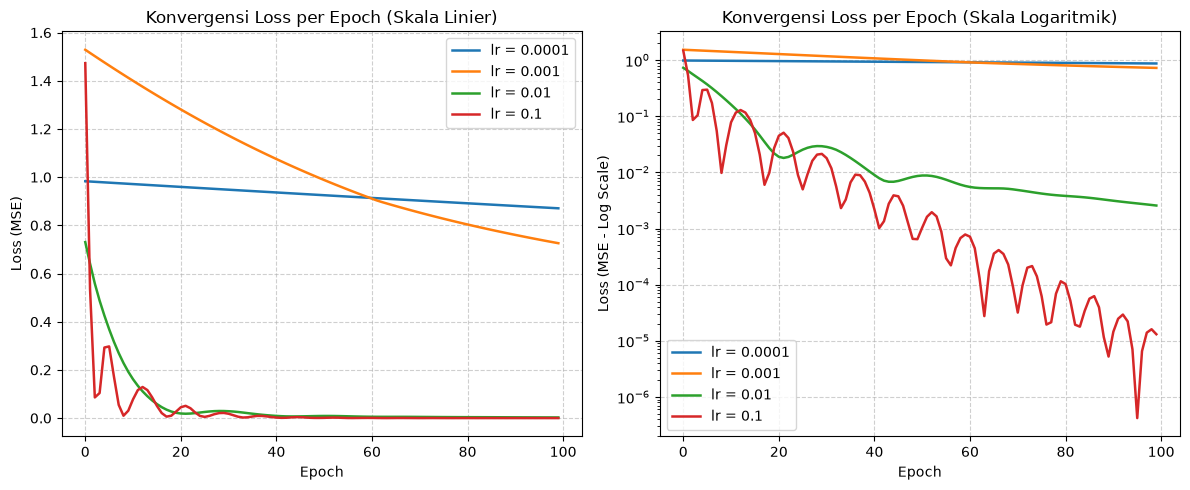

In [3]:
# 1. Tabel Perbandingan Hasil Loss
df_tugas4 = pd.DataFrame({
    "Learning Rate": [f"{lr}" for lr in learning_rates],
    "Train Loss Awal (Epoch 1)": [f"{histories_lr[lr][0]:.6f}" for lr in learning_rates],
    "Train Loss Akhir (Epoch 100)": [f"{histories_lr[lr][-1]:.6f}" for lr in learning_rates],
    "Test Loss Evaluasi (MSE)": [f"{test_losses_lr[lr]:.6f}" for lr in learning_rates]
})

print("=" * 80)
print("=== TABEL PERBANDINGAN HASIL LOSS DENGAN VARIASI LEARNING RATE ===")
print("=" * 80)
display(df_tugas4)

# 2. Visualisasi Grafik Konvergensi Loss
plt.figure(figsize=(12, 5))

# Subplot 1: Skala Linier
plt.subplot(1, 2, 1)
for lr in learning_rates:
    plt.plot(histories_lr[lr], label=f"lr = {lr}", linewidth=1.8)
plt.title("Konvergensi Loss per Epoch (Skala Linier)", fontsize=12)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss (MSE)", fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)

# Subplot 2: Skala Logaritmik
plt.subplot(1, 2, 2)
for lr in learning_rates:
    plt.semilogy(histories_lr[lr], label=f"lr = {lr}", linewidth=1.8)
plt.title("Konvergensi Loss per Epoch (Skala Logaritmik)", fontsize=12)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss (MSE - Log Scale)", fontsize=10)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### Pembahasan Tugas 4:
- **Learning Rate Terlalu Kecil ($\text{lr} = 0.0001$):** Penurunan loss berjalan sangat lambat. Dalam 100 epoch, model belum konvergen sempurna sehingga menyisakan nilai loss yang relatif tinggi.
- **Learning Rate Standar ($\text{lr} = 0.001$):** Konvergensi berlangsung stabil dan teratur, menghasilkan penurunan loss yang baik secara bertahap.
- **Learning Rate Lebih Besar ($\text{lr} = 0.01$ dan $\text{lr} = 0.1$):** Model belajar jauh lebih cepat pada data regresi linier sederhana ini. Dengan $\text{lr} = 0.1$, model mampu mencapai penurunan loss yang sangat drastis dalam beberapa epoch awal dan mencapai nilai MSE mendekati nol ($< 10^{-6}$).
- **Kesimpulan:** *Learning rate* mengontrol seberapa besar langkah pembaruan bobot di setiap iterasi. Nilai learning rate yang tepat mempercepat model mencapai titik minimum loss tanpa mengalami osilasi atau divergensi.

---
# Praktikum Lanjutan: Prediksi Harga Rumah Menggunakan Dataset Boston (MLP Regresi)

Praktikum berikut akan menggunakan data Boston untuk memprediksi harga rumah menggunakan Multi-Layer Perceptron (MLP) dengan Keras.

Dataset Boston berhasil dimuat: 506 baris data dan 13 fitur input.


c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

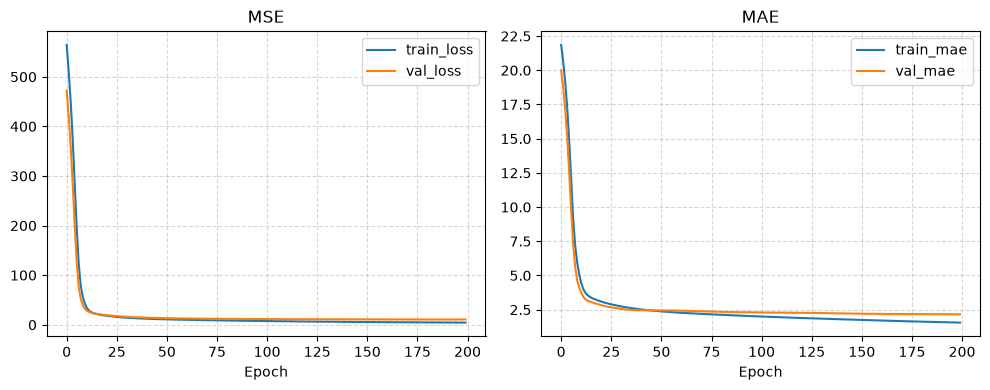

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Evaluasi Akhir Model Boston Housing:
RMSE : 3.2799
MAE  : 2.1596


In [4]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# 1. Load dataset Boston Housing
try:
    from sklearn.datasets import load_boston
    data = load_boston()
    X = data.data
    y = data.target
except (ImportError, Exception):
    # Alternatif resmi jika load_boston sudah dihapus di scikit-learn versi 1.2+
    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
    X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    y = raw_df.values[1::2, 2]

print(f"Dataset Boston berhasil dimuat: {X.shape[0]} baris data dan {X.shape[1]} fitur input.")

# 2. Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])
model.summary()

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')
plt.xlabel('Epoch')
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.xlabel('Epoch')
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 6. Evaluasi Nilai Prediksi dan Hitung RMSE
pred = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"Evaluasi Akhir Model Boston Housing:")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {h.history['val_mae'][-1]:.4f}")

### Kesimpulan Praktikum 3:
1. **Regresi Menggunakan JST:** Pada masalah regresi, neuron lapisan keluaran (*output layer*) tidak menggunakan fungsi aktivasi non-linear (atau menggunakan aktivasi linier) dengan fungsi kerugian *Mean Squared Error* (MSE).
2. **Pengaruh Learning Rate:** *Learning rate* menentukan stabilitas dan kecepatan konvergensi saat optimasi model regresi. Nilai yang terlalu kecil membuat proses belajar lambat, sementara nilai yang tepat menghasilkan penurunan loss yang signifikan.
3. **Model MLP pada Kasus Nyata (Boston Housing):** Arsitektur Multi-Layer Perceptron (Dense 64 -> Dense 32 -> Dense 1) yang dilatih dengan optimizer Adam mampu menangkap pola hubungan non-linear antara fitur fisik lingkungan perumahan terhadap nilai harga rumah dengan nilai RMSE yang rendah.